# Homework assignment #3

**YOUR NAME**


You are free to use any code developed in the class or the textbook.

When your solution contains computer code, please submit the work as a Jupyter notebook. Please write your name near the top of the notebook - where it says "YOUR NAME" above.

If your solution contains hand-written calculations, it is probably easiest to submit these on paper in class. You can type mathematics using LaTeX expressions between dollar signs (if you [know how to do that](https://towardsdatascience.com/write-markdown-latex-in-the-jupyter-notebook-10985edb91fd)), but hand-written is usually easier and is fine.

All question numbers refer to exercises in the textbook.

## Q 4.1.3

For the third equaton and given interval ($e^{x+1} = x+2$, $[-2 ,2]$), do the following steps.

(a) Rewrite the equation into the standard form for rootfinding, $f(x)=0$. 
Make a plot of $f$ over the given interval and determine how many roots lie in the interval.

(b) Use `nlsolve` to find each root, as shown in Demo 4.1.2.

(c) Compute the condition number of each root found in part (b)

Hint: don't forget to use broadcasting (@.) in your definition of the function used for root finding with nlsolve.


**(a)** $f(x) = e^{x+1}-x-2$ , then $x$ such that $f(x)=0$ is the solution to the equation.

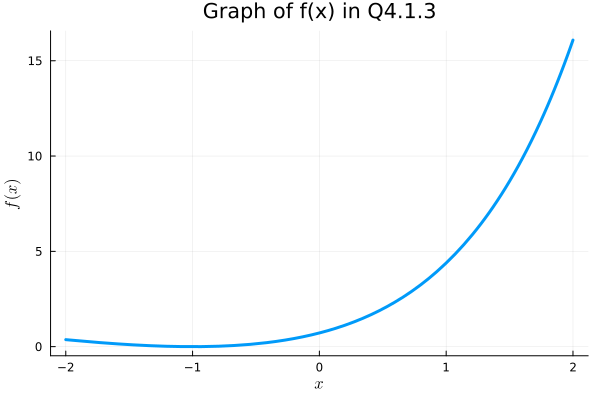

In [55]:
using Plots
using Roots
using LaTeXStrings

# (a)
f1(x) = exp(x + 1) - x - 2

plot(f1, -2, 2, 
    title="Graph of f(x) in Q4.1.3", 
    label=nothing,
    linewidth=3,
    xlabel=(L"x"),
    ylabel=(L"f(x)")
    # labelfont=font(14, "Fira Code")
    )

From the graph, it's not sufficient to determine the number of roots, so we'll plot $f'(x)$ and zoom into $[-1.5,-0.5]$ to see the details.

$f'(x) = \exp(x+1)-1 $, hence $f'(x)<0$ when $x<0$, $f'(x)=0$ when $x=-1$ and $f'(x)> 0$ otherwise. Thus $f(x)$ decreases monotoniously on $[-2,-1]$ and increases monotoniously on $[-1,2]$. 

Since $f(-1)=0$, hence there's only one roots of $f(x)$. I.e. the equation has the only solution $x=-1$.

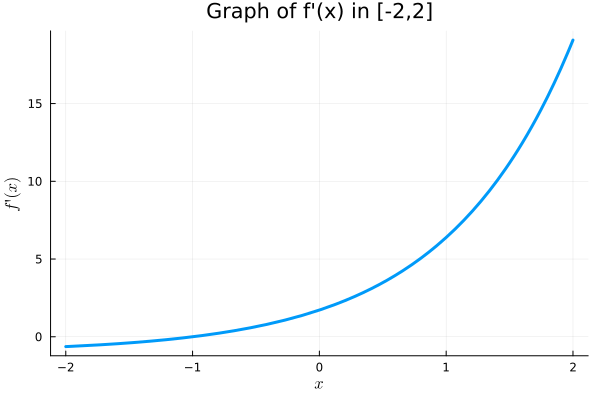

In [56]:
f1p(x) = exp(x + 1) - 1

plot(f1p, -2, 2, 
    title="Graph of f'(x) in [-2,2]", 
    label=nothing,
    linewidth=3,
    xlabel=(L"x"),
    ylabel=(L"f'(x)")
    # labelfont=font(14, "Fira Code")
    )

**(b)** The root is $x\approx -0.1000$.

In [2]:
# (b)
using NLsolve;

guess = -0.8; # a biased initial value
nlsolve(x->f1(x[1]), [guess], ftol=1e-14)

Results of Nonlinear Solver Algorithm
 * Algorithm: Trust-region with dogleg and autoscaling
 * Starting Point: [-0.8]
 * Zero: [-0.999999897472629]
 * Inf-norm of residuals: 0.000000
 * Iterations: 21
 * Convergence: true
   * |x - x'| < 0.0e+00: false
   * |f(x)| < 1.0e-14: true
 * Function Calls (f): 22
 * Jacobian Calls (df/dx): 22

**(c)** The condition number around the root $x=-1$ is $\lim_{\varepsilon \rightarrow 0}\sup_{||\delta x||\leqslant \varepsilon}\dfrac{||\delta x||}{||\delta f(x)||}=f'(-1)^{-1}=\infty$.

In [28]:
f1p(-1)

0.0

## Q 4.1.4

 A basic safe type of investment is an annuity: one makes monthly deposits of size $P$ for $n$
 months at a fixed annual interest rate $r$, and at maturity collects the amount
$$\frac{12P}{r}\left(\left(1+\frac{r}{12}\right)^n-1\right)$$

(This is not the definition of annuity that you may be familiar with, but the calculation is part of any accumulation of funds over time.)

Say you want to create an annuity for a term of 300 months and final value of 1,000,000 dollars. 
Using nlsolve, make a table of the interest rate you will need to get for each of the different 
contribution values $P = 500 + 50k$, $k = 0, \dots, 10$.



Hint: if you write a function for the value of annuity, or the difference between this value and one million dollars with several arguments $(P, r, n)$, you can then create a new function of just the one variable $r$ for each value of $P$ in a loop. The table and pretty tables approach used in homework 2 will be helpful here.

In [58]:
Ps = collect(500:50:1000);
n = 300;

res = [];
for P = Ps
    meet = r -> 12 * P / r * ((1 + r / 12) ^ n - 1) - 1e6;
    s = nlsolve(x->meet(x[1]), [0.5], ftol=1e-14);
    append!(res, s.zero)
end

In [59]:
using PrettyTables;

pretty_table(
    [Ps res], header=(["P", "solution r"])
)

┌──────┬────────────┐
│    P │ solution r │
├──────┼────────────┤
│  500 │   0.123512 │
│  550 │   0.118146 │
│  600 │     0.1132 │
│  650 │   0.108607 │
│  700 │   0.104317 │
│  750 │   0.100287 │
│  800 │  0.0964849 │
│  850 │  0.0928838 │
│  900 │  0.0894611 │
│  950 │  0.0861978 │
│ 1000 │  0.0830778 │
└──────┴────────────┘


## Q 4.1.6

Lambert's $W$  function is defined as the inverse of $xe^x$. That is, $y=W(x)$ if and only if 
$x=ye^y$. Write a function `lambertW` that computes $W$ using nlsolve. Make a plot of $W$ for 
$0 \leq x \leq 4$.

Hint: If you create a function that returns the `.zero` part of a solution from `nlsolve`, remember that the zero is a vector (since nlsolve works for vector valued functions). You can't plot a vector, so you will want something like `s = nlsolve ...` then `s.zero[1]` in your `lambertW` function.

Check on [Wikipedia](https://en.wikipedia.org/wiki/Lambert_W_function) to see if you got it right.

In [90]:
function lambertW(x)
    sol = nlsolve(y->x - y[1] * exp(y[1]), [0.0], ftol=1e-14);
    return sol.zero[1];
end

lambertW (generic function with 1 method)

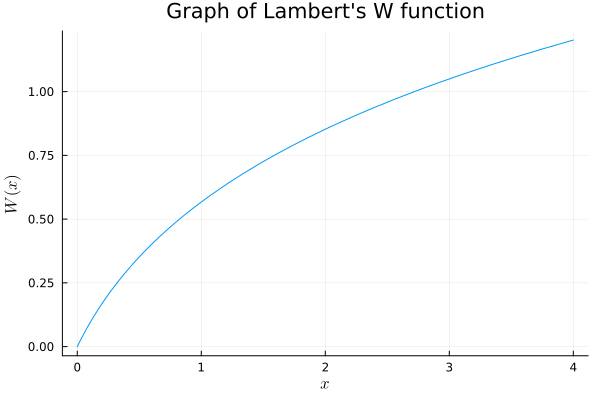

In [94]:
# Plot
plot(lambertW, 0, 4, 
    label=nothing, title="Graph of Lambert's W function", xlabel=(L"x"), ylabel=(L"W(x)")
)

## Q 4.3.5

Show that if $f(x) = x^{-1}-b$ for nonzero $b$, then Newton's iteration converging to the root $r=1/b$ can be implemented without performing any divisions.
 
Write and test a Julia function to compute reciprocals without dividing. Your function doesn't have to work with any guess; you can start with a "good" one. It also doesn't need to work on any input, but you should show it works on some inputs.


If $f(x)=0$ $f$ has exact the same and unique positive root. Consider the Newton's iteration formula for $f(x)$, we have

$$x_{n+1}=x_n-\dfrac{f(x_n)}{f'(x_n)}=2x_{n}-bx_n^2$$

A good initial value is $x_0\in(1,\dfrac{1}{2b})$, to avoid division, we let $x_0=1e-4b$.

Let $\varphi(x)=2x-bx^2$, then $||x_{n+1}-\dfrac{1}{b}||=|b|||x_n-\dfrac{1}{b}||^2$, hence for $b\in(0,1)$, it must converges (second order).

In [47]:
function solve(phi, x0, tol, N)
    n = 0;
    x1 = x0;
    x0 = 99999;
    while abs(x0 - x1) > tol && n < N
        x0 = x1;
        x1 = phi(x1);
        # println("{}\t{}\t{}", [n, x0, x1]);
        n = n + 1;
    end
    return x1;
end

solve (generic function with 1 method)

In [53]:
bs = collect(0.1:0.1:0.9)
res = []
for b = bs
    phi = x -> 2 * x - b * x ^ 2;
    sol = solve(phi, 1e-4 * b, 1e-14, 1000);
    append!(res, sol)
end

In [54]:
pretty_table(
    [bs res (bs.^(-1))], header=(["b", "solution x", "expected"])
)

┌─────┬────────────┬──────────┐
│   b │ solution x │ expected │
├─────┼────────────┼──────────┤
│ 0.1 │       10.0 │     10.0 │
│ 0.2 │        5.0 │      5.0 │
│ 0.3 │    3.33333 │  3.33333 │
│ 0.4 │        2.5 │      2.5 │
│ 0.5 │        2.0 │      2.0 │
│ 0.6 │    1.66667 │  1.66667 │
│ 0.7 │    1.42857 │  1.42857 │
│ 0.8 │       1.25 │     1.25 │
│ 0.9 │    1.11111 │  1.11111 │
└─────┴────────────┴──────────┘



## Q 4.3.8

In Function 4.3.6 and elsewhere, the actual error is not available, so we use $|x_k-x_{k-1}|$ as
 an approximate indicator of error to determine when to stop the iteration. Find an example that foils 
 this indicator; that is, a sequence $\{x_k\}$ such that
$$\lim_{k\to\infty} (x_k-x_{k-1})= 0,$$
but $\{x_k\}$ diverges. 
(Hint: You have seen such sequences in calculus.) 
Hence the need for residual tolerances and safety valves in the code!

Let $\displaystyle x_n=\sum_{i=1}^n\dfrac{1}{i}$, then 

$$\displaystyle\lim_{k\to \infty}(x_k-x_{k-1})=\displaystyle\lim_{k\to \infty}\dfrac{1}{k}=0$$

but $\forall\ n\in\mathbb{N}$, we have

$$x_n=\sum_{i=1}^n\dfrac{1}{i}\geqslant\sum_{i=1}^{2^{\lfloor \log_2 (n-1)\rfloor}-1}>1+\dfrac{1}{2}+\dfrac{1}{2}+\dfrac{1}{4}+\cdots=\lfloor\log_2(n-1)\rfloor-1=+\infty$$

i.e $\{x_n\}$ diverges.


## Q 4.5.6

Any three noncollinear points in the plane determine a unique circle. Suppose the points are given as 
$(x_i, y_i)$ for $i = 1, 2, 3$. We can define the circle in terms of its center 
$(a,b)$ and radius $r$. Then
$$f_i(a,b,r)= (a-x_i)^2 + (b-y_i)^2 - r^2$$
should be made zero for all $i=1,2,3$. This defines a nonlinear system 
$f(v) = 0$ for 
$v=[a,b,r]$.

Use Function 4.5.5 (Newton's method for systems) on this system to find the circle passing through 
$(-5,0)$, $(1,-3)$, and $(4,2)$. Make a plot that shows you found the correct circle.

Hint: you can draw a circle using the `circle` function written below and by giving the center and radius. See example below. I've given you the `newtonsys` function from the text below.

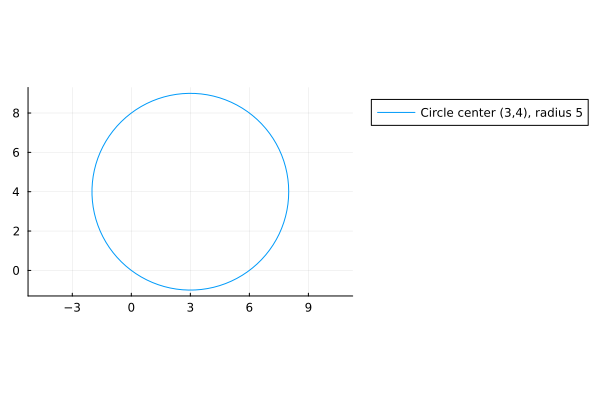

In [67]:
using Plots
function circle(x)
  a,b,r = x
  theta = range(0, 2.0*pi, length = 100)
  @. a + r*cos(theta), b + r*sin(theta)
end
plot(circle([3,4,5]), aspect_ratio = 1, 
     label = "Circle center (3,4), radius 5",
     legend = :outertopright)

In [66]:
using LinearAlgebra
"""
    newtonsys(f,jac,x₁[;maxiter,ftol,xtol])

Use Newton's method to find a root of a system of equations,
starting from `x₁`. The functions `f` and `jac` should return the
residual vector and the Jacobian matrix, respectively. Returns the
history of root estimates as a vector of vectors.

The optional keyword parameters set the maximum number of iterations
and the stopping tolerance for values of `f` and changes in `x`.

"""
function newtonsys(f,jac,x₁;maxiter=40,ftol=1000*eps(),xtol=1000*eps())
    x = [float(x₁)]
    y,J = f(x₁),jac(x₁)
    Δx = Inf   # for initial pass below
    k = 1

    while (norm(Δx) > xtol) && (norm(y) > ftol)
        Δx = -(J\y)             # Newton step
        push!(x,x[k] + Δx)    # append to history
        k += 1
        y,J = f(x[k]),jac(x[k])

        if k==maxiter
            @warn "Maximum number of iterations reached."
            break
        end
    end
    return x
end

newtonsys

In [125]:
function jac(pts, c)
    # xs 
    # [[x1, y1]]
    # [[x2, y2]]
    # [[x3, y3]]
    
    mat = zeros(3, 3);
    for i = 1:3
        mat[i, 1] = -2. * (pts[i, 1] - c[1]);
        mat[i, 2] = -2. * (pts[i, 2] - c[2]);
        mat[i, 3] = -2. * c[3];
    end
    
    return mat;
end

function f(pts, c)
    F = [0., 0., 0.];
    for i = 1:3
        F[i] = (pts[i, 1] - c[1]) ^ 2 + (pts[i, 2] - c[2]) ^ 2 - c[3] ^ 2;
    end
    return F;
end

f (generic function with 1 method)

In [126]:
pts = [[-5., 0.] [1., -3.] [4., 2.]]';

f_in = c -> f(pts, c);
jac_in = c -> jac(pts, c);

In [128]:
c = [1., 1., 1.]

res = newtonsys(f_in, jac_in, c)

8-element Vector{Vector{Float64}}:
 [1.0, 1.0, 1.0]
 [-0.5769230769230769, 1.3461538461538463, 9.884615384615385]
 [-0.576923076923075, 1.346153846153844, 6.023570787189463]
 [-0.5769230769230766, 1.346153846153846, 4.786126594202097]
 [-0.576923076923077, 1.3461538461538465, 4.626157138670653]
 [-0.576923076923077, 1.3461538461538458, 4.623391319661922]
 [-0.5769230769230773, 1.3461538461538463, 4.623390492373654]
 [-0.5769230769230765, 1.3461538461538454, 4.62339049237358]

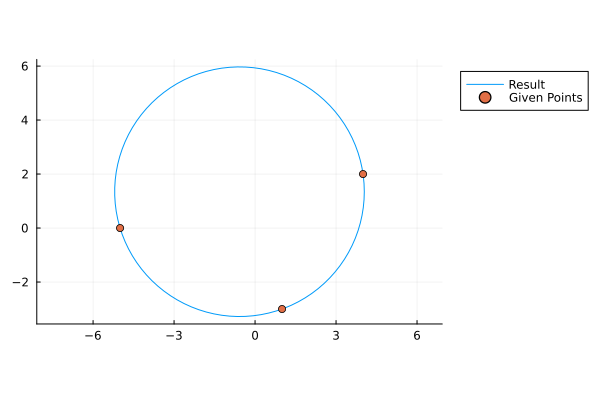

In [134]:
plot(circle(res[end]'), aspect_ratio = 1, 
     label = "Result",
     legend = :outertopright)
scatter!(pts[:, 1], pts[:, 2], label="Given Points")

Hence the circle we found is correct.

## Q 4.7.4

(Variation on Exercise 4.5.6.) Suppose the points $(x_i, y_i)$ for $i = 1, \dots, m$ are given, and the goal
is to find the circle with center $(a,b)$ and radius $r$
that best fits the points. Define
$$f_i(a,b,r) = (a-x_i)^2 +(b-y_i)^2 - r^2, \ \ i =1, \dots, m.$$
Then we can define the best circle as the one that minimizes $\|f\|_2$.

Define data points as follows:


In [164]:
m = 30; ts = 2π*rand(m);
xs = @. -2 + 5*cos(ts); ys = @. 1 + 5*sin(ts);
xs += 0.2*randn(m); ys += 0.2*randn(m); # add some random variation to the points on the circle


Use Function 4.6.4 (Levenberg, plus finite-difference Jacobian) to find the best-fit circle, and make a plot of the circle superimposed on the points.



In [229]:
"""
    fdjac(f,x₀[,y₀])

Compute a finite-difference approximation of the Jacobian matrix for
`f` at `x₀`, where `y₀`=`f(x₀)` may be given.
"""
function fdjac(f,x₀,y₀=f(x₀))
    δ = sqrt(eps())*max(norm(x₀),1)   # FD step size
    m,n = length(y₀),length(x₀)
    if n==1
        J = (f(x₀+δ) - y₀) / δ
    else
        J = zeros(m,n)
        x = copy(x₀)
        for j in 1:n
            x[j] += δ
            J[:,j] = (f(x) - y₀) / δ
            x[j] -= δ
        end
    end
    return J
end
"""
    levenberg(f,x₁[;maxiter,ftol,xtol])

Use Levenberg's quasi-Newton iteration to find a root of the system
`f` starting from `x₁`. Returns the history of root estimates 
as a vector of vectors.

The optional keyword parameters set the maximum number of iterations
and the stopping tolerance for values of `f` and changes in `x`.

"""
function levenberg(f,x₁;maxiter=40,ftol=1e-12,xtol=1e-12)
    x = [x₁]
    yₖ = f(x₁)
    k = 1;  s = Inf;
    A = fdjac(f,x[k],yₖ)   # start with FD Jacobian
    jac_is_new = true

    λ = 10;
    while (norm(s) > xtol) && (norm(yₖ) > ftol)
        # Compute the proposed step.
        B = A'*A + λ*I
        z = A'*yₖ
        s = -(B\z)
        
        x̂ = x[k] + s' #! HERE, I ADDED A TRANSPOSITION
        ŷ = f(x̂)

        # Do we accept the result?
        if norm(ŷ) < norm(yₖ)    # accept
            λ = λ/10   # get closer to Newton
            # Broyden update of the Jacobian.
            A += (ŷ-yₖ-A*s)*(s'/(s'*s))
            jac_is_new = false
            
            push!(x,x̂)
            yₖ = ŷ
            k += 1
        else                       # don't accept
            # Get closer to gradient descent.
            λ = 4λ
            # Re-initialize the Jacobian if it's out of date.
            if !jac_is_new
                A = fdjac(f,x[k],yₖ)
                jac_is_new = true
            end
        end

        if k==maxiter
            @warn "Maximum number of iterations reached."
            break
        end
        
    end
    return x
end

levenberg

In [230]:
function eval(xs, ys, c)
    F = [(xs[i] - c[1]) ^ 2 + (ys[i] - c[2]) ^ 2 - c[3] ^ 2 for i in 1:length(xs)];
    return F
end

eval (generic function with 3 methods)

In [231]:
c = [1. 1. 1.];

res = levenberg(coeffs -> eval(xs, ys, coeffs'), c)

10-element Vector{Matrix{Float64}}:
 [1.0 1.0 1.0]
 [-2.047650713578339 0.9511589804292205 7.924295516757582]
 [-1.9083900498746176 0.9715363469077393 2.489508073741508]
 [-1.9133033927271703 0.9704601481968057 4.363356909565019]
 [-1.9132000567359626 0.97048356215014 5.288917052490743]
 [-1.9131916326291851 0.9704854780065302 5.018424958229337]
 [-1.9131918043228995 0.970485438968882 5.035585930651938]
 [-1.9131918033113637 0.9704854391988822 5.036018052607194]
 [-1.9131918033087465 0.9704854391994773 5.036017293548955]
 [-1.9131918048928205 0.9704854367749596 5.036017293741843]

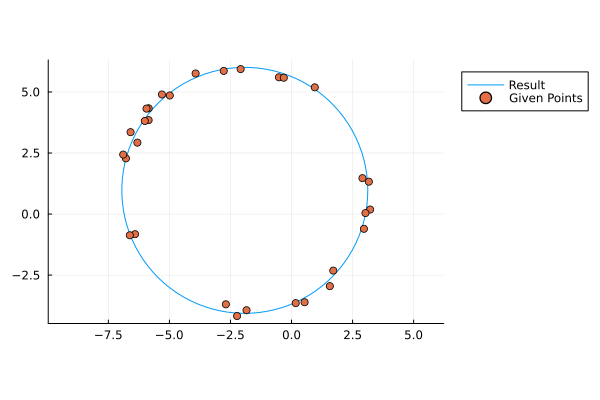

In [232]:
plot(circle(res[end]'), aspect_ratio = 1, 
     label = "Result",
     legend = :outertopright)
scatter!(xs, ys, label="Given Points")

In [236]:
println("Least 2-Norm: ", norm(eval(xs, ys, res[end]), 2))

Least 2-Norm: 8.177347587073655
